# 🩺 Chẩn Đoán Bệnh Cây Cảnh: Hệ Thống Huấn Luyện AI Tiêu Chuẩn (Enterprise Pipeline)

Hệ thống huấn luyện Deep Learning chuyên sâu cho **5 nhóm bệnh lá cây cảnh phổ biến** (Floria AI):
- `Anthracnose` (Bệnh Thán Thư lá kiểng)
- `Bacterial_Blight` (Cháy bìa lá / Thối nhũn vi khuẩn)
- `Healthy` (Lá khỏe mạnh, không bệnh)
- `Leaf_Spot` (Bệnh đốm lá nấm Cercospora/Alternaria)
- `Powdery_Mildew` (Bệnh phấn trắng)

**Đặc tính kỹ thuật**:
- Tự động tích hợp dữ liệu (KaggleHub: PlantDoc + Mango Leaf Disease)
- Chia tập dữ liệu Stratified Split 80/10/10 & WeightedRandomSampler chống mất cân bằng lớp
- Huấn luyện đa mô hình tự động nối tiếp: `mobilenetv3_large_100`, `tf_efficientnetv2_b0`, `ghostnetv2_100`
- Mixed Precision (FP16), Auto-Resume chống sập kết nối Colab
- Báo cáo trực quan học thuật (Master Dashboard: Confusion Matrix, ROC Curve, FPS, Latency)
- Tự động xuất mô hình ONNX, TorchScript và lưu đồng bộ vào Google Drive.

In [ ]:
# ==============================================================================
# CHƯƠNG 1: THIẾT LẬP MÔI TRƯỜNG, GPU & DỮ LIỆU TỰ ĐỘNG
# ==============================================================================
import os
import sys
import shutil
import random
import subprocess
from pathlib import Path
from PIL import Image

try:
    from google.colab import drive
    IN_COLAB = True
    drive.mount('/content/drive')
except ImportError:
    IN_COLAB = False
    print("CẢNH BÁO: Môi trường hiện tại không phải là Google Colab.")

def check_gpu():
    import torch
    if not torch.cuda.is_available():
        raise Exception("KHÔNG TÌM THẤY GPU! Vui lòng chuyển Runtime của Colab sang GPU (T4, L4, hoặc A100).")
    gpu_name = torch.cuda.get_device_name(0)
    vram = torch.cuda.get_device_properties(0).total_memory / 1024**3
    print(f"Đã nhận diện GPU: {gpu_name} (Tổng VRAM: {vram:.2f} GB)")

def install_deps():
    print("Đang cài đặt các thư viện MLOps cần thiết (vui lòng đợi)...")
    cmd = "pip install -q timm albumentations torchmetrics onnx onnxruntime kagglehub scikit-learn"
    subprocess.run(cmd, shell=True)
    print("Cài đặt thư viện hoàn tất!")

def prepare_disease_dataset():
    import kagglehub
    dataset_root = Path("/content/disease_dataset")
    zip_path = Path("/content/drive/MyDrive/Dudoancaycanh_Disease/dataset_disease.zip")

    if zip_path.exists():
        print(f"Tìm thấy dữ liệu sẵn trên Google Drive: {zip_path}")
        if not dataset_root.exists() or len(os.listdir(dataset_root)) == 0:
            print("Đang giải nén dữ liệu từ Google Drive...")
            subprocess.run(f"unzip -q '{zip_path}' -d '{dataset_root}'", shell=True)
            print("Giải nén hoàn tất!")
            return str(dataset_root)

    if dataset_root.exists() and len(os.listdir(dataset_root)) >= 5:
        print(f"Bộ dữ liệu 5 nhóm bệnh đã sẵn sàng tại {dataset_root}")
        return str(dataset_root)

    print("\n--- TỰ ĐỘNG TỔNG HỢP 5 NHÓM BỆNH TỪ KAGGLEHUB ---")
    print("1. Tải PlantDoc và Mango datasets...")
    plantdoc_path = Path(kagglehub.dataset_download("nirmalsankalana/plantdoc-dataset"))
    mango_path = Path(kagglehub.dataset_download("aryashah2k/mango-leaf-disease-dataset"))
    print("Đã tải dữ liệu về cache thành công!")

    CLASSES = ["Anthracnose", "Bacterial_Blight", "Healthy", "Leaf_Spot", "Powdery_Mildew"]
    for c in CLASSES:
        (dataset_root / c).mkdir(parents=True, exist_ok=True)

    def get_images(folder):
        imgs = []
        if not folder.exists():
            return imgs
        for root, _, files in os.walk(folder):
            for f in files:
                if f.lower().endswith(('.jpg', '.jpeg', '.png', '.webp')):
                    imgs.append(Path(root) / f)
        return imgs

    collected = {c: [] for c in CLASSES}
    collected["Anthracnose"].extend(get_images(mango_path / "Anthracnose"))
    collected["Powdery_Mildew"].extend(get_images(mango_path / "Powdery Mildew"))
    for s in ["train", "test"]:
        collected["Powdery_Mildew"].extend(get_images(plantdoc_path / s / "Squash_Powdery_mildew_leaf"))

    collected["Healthy"].extend(get_images(mango_path / "Healthy"))
    healthy_folders = ["Apple_leaf", "Bell_pepper_leaf", "Blueberry_leaf", "Cherry_leaf", "grape_leaf", "Peach_leaf", "Raspberry_leaf", "Soyabean_leaf", "Strawberry_leaf", "Tomato_leaf"]
    for s in ["train", "test"]:
        for h in healthy_folders:
            collected["Healthy"].extend(get_images(plantdoc_path / s / h))

    spot_folders = ["Bell_pepper_leaf_spot", "Corn_Gray_leaf_spot", "Tomato_Septoria_leaf_spot"]
    for s in ["train", "test"]:
        for sf in spot_folders:
            collected["Leaf_Spot"].extend(get_images(plantdoc_path / s / sf))

    blight_folders = ["Corn_leaf_blight", "Potato_leaf_early_blight", "Potato_leaf_late_blight", "Tomato_Early_blight_leaf", "Tomato_leaf_bacterial_spot", "Tomato_leaf_late_blight"]
    for s in ["train", "test"]:
        for bf in blight_folders:
            collected["Bacterial_Blight"].extend(get_images(plantdoc_path / s / bf))

    max_per_class = 500
    random.seed(42)
    print("\n--- THỐNG KÊ DỮ LIỆU ĐÃ TỔNG HỢP ---")
    for c in CLASSES:
        all_imgs = collected[c]
        random.shuffle(all_imgs)
        selected = all_imgs[:max_per_class]
        for idx, src in enumerate(selected):
            dst = dataset_root / c / f"{c}_{idx:04d}{src.suffix.lower()}"
            shutil.copy2(src, dst)
        print(f"[{c}]: Đã chắt lọc {len(selected):,} ảnh sạch")

    return str(dataset_root)

install_deps()
check_gpu()
DATASET_PATH = prepare_disease_dataset()
print("\n===================================")
print("HỆ THỐNG & DỮ LIỆU ĐÃ SẴN SÀNG!")
print("===================================")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Đang cài đặt các thư viện MLOps cần thiết (vui lòng đợi)...
Cài đặt thư viện hoàn tất!
Đã nhận diện GPU: Tesla T4 (Tổng VRAM: 14.56 GB)
Bộ dữ liệu 5 nhóm bệnh đã sẵn sàng tại /content/disease_dataset

HỆ THỐNG & DỮ LIỆU ĐÃ SẴN SÀNG!


In [ ]:
# ==============================================================================
# CHƯƠNG 2: CẤU HÌNH DỰ ÁN TẬP TRUNG (MASTER CONFIG)
# ==============================================================================
import torch
import random
import numpy as np
import logging
import os

PROJECT_NAME     = "ChanDoanBenhCayCanh"

# Danh sách các mô hình tối ưu cho Thiết bị Di động & CPU Inference:
MODELS_TO_TRAIN  = ["mobilenetv3_large_100", "tf_efficientnetv2_b0", "ghostnetv2_100"]

PRETRAINED       = True
IMAGE_SIZE       = 224
BATCH_SIZE       = 32
EPOCHS           = 15
LEARNING_RATE    = 1e-3
BACKBONE_LR      = 1e-4
WEIGHT_DECAY     = 1e-2
DROPOUT_RATE     = 0.4
MIXED_PRECISION  = True

# Đường dẫn lưu trữ (Đồng bộ trực tiếp với Google Drive)
DRIVE_ROOT       = "/content/drive/MyDrive/Dudoancaycanh_Disease" if IN_COLAB else "./Dudoancaycanh_Disease"

DIRS = {
    "models": os.path.join(DRIVE_ROOT, "models"),
    "checkpoints": os.path.join(DRIVE_ROOT, "checkpoints"),
    "exports": os.path.join(DRIVE_ROOT, "exports"),
    "reports": os.path.join(DRIVE_ROOT, "reports"),
    "experiments": os.path.join(DRIVE_ROOT, "experiments")
}
for d in DIRS.values():
    os.makedirs(d, exist_ok=True)

def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True

seed_everything(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Cấu hình hoàn tất! Sẽ huấn luyện lần lượt các kiến trúc: {MODELS_TO_TRAIN}")
print(f"Thư mục lưu trữ kết quả trên Drive: {DRIVE_ROOT}")

Cấu hình hoàn tất! Sẽ huấn luyện lần lượt các kiến trúc: ['mobilenetv3_large_100', 'tf_efficientnetv2_b0', 'ghostnetv2_100']
Thư mục lưu trữ kết quả trên Drive: /content/drive/MyDrive/Dudoancaycanh_Disease


In [ ]:
# ==============================================================================
# CHƯƠNG 3: DATA PIPELINE (STRATIFIED SPLIT 80/10/10 & WEIGHTED SAMPLER)
# ==============================================================================
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, WeightedRandomSampler
from sklearn.model_selection import train_test_split
import copy

full_dataset = datasets.ImageFolder(DATASET_PATH)
classes = full_dataset.classes
NUM_CLASSES = len(classes)

print("======================================================")
print("BÁO CÁO PHÂN TÍCH BỘ DỮ LIỆU BỆNH CÂY CẢNH")
print("======================================================")
print(f"Số lượng nhóm bệnh: {NUM_CLASSES} nhóm ({classes})")
print(f"Tổng số lượng ảnh: {len(full_dataset):,} bức ảnh")

DATASET_MEAN = [0.485, 0.456, 0.406]
DATASET_STD = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE + 32, IMAGE_SIZE + 32)),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.15),
    transforms.RandomCrop(IMAGE_SIZE),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(DATASET_MEAN, DATASET_STD),
    transforms.RandomErasing(p=0.3, scale=(0.02, 0.08))
])

val_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(DATASET_MEAN, DATASET_STD)
])

# Chia Stratified Split 80% Train, 10% Val, 10% Test
targets = [s[1] for s in full_dataset.samples]
train_idx, temp_idx = train_test_split(np.arange(len(targets)), test_size=0.2, stratify=targets, random_state=42)
temp_targets = [targets[i] for i in temp_idx]
val_idx, test_idx = train_test_split(temp_idx, test_size=0.5, stratify=temp_targets, random_state=42)

train_ds = copy.deepcopy(full_dataset); train_ds.samples = [full_dataset.samples[i] for i in train_idx]; train_ds.transform = train_transform
val_ds   = copy.deepcopy(full_dataset); val_ds.samples   = [full_dataset.samples[i] for i in val_idx];   val_ds.transform   = val_transform
test_ds  = copy.deepcopy(full_dataset); test_ds.samples  = [full_dataset.samples[i] for i in test_idx];  test_ds.transform  = val_transform

# Weighted Random Sampler cân bằng trọng số giữa các nhóm bệnh
class_counts_train = [0] * NUM_CLASSES
for _, label in train_ds.samples: class_counts_train[label] += 1
class_weights = [len(train_idx) / (NUM_CLASSES * c) if c > 0 else 0 for c in class_counts_train]
weights = [class_weights[label] for _, label in train_ds.samples]
sampler = WeightedRandomSampler(weights, num_samples=len(weights), replacement=True)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, sampler=sampler, num_workers=2, pin_memory=True, drop_last=True, persistent_workers=True)
val_loader   = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True, persistent_workers=True)
test_loader  = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True, persistent_workers=True)

print("\n======================================================")
print("CẤU TRÚC PHÂN BỔ DỮ LIỆU (STRATIFIED SPLIT)")
print("======================================================")
print(f"Tập Huấn Luyện (Train): {len(train_idx):,} ảnh")
print(f"Tập Kiểm Chứng (Val):   {len(val_idx):,} ảnh")
print(f"Tập Đánh Giá (Test):    {len(test_idx):,} ảnh (Tuyệt mật - Đánh giá khách quan)")
print("Data Pipeline đã sẵn sàng đưa vào Huấn luyện!")

BÁO CÁO PHÂN TÍCH BỘ DỮ LIỆU BỆNH CÂY CẢNH
Số lượng nhóm bệnh: 5 nhóm (['Anthracnose', 'Bacterial_Blight', 'Healthy', 'Leaf_Spot', 'Powdery_Mildew'])
Tổng số lượng ảnh: 2,307 bức ảnh

CẤU TRÚC PHÂN BỔ DỮ LIỆU (STRATIFIED SPLIT)
Tập Huấn Luyện (Train): 1,845 ảnh
Tập Kiểm Chứng (Val):   231 ảnh
Tập Đánh Giá (Test):    231 ảnh (Tuyệt mật - Đánh giá khách quan)
Data Pipeline đã sẵn sàng đưa vào Huấn luyện!



ĐANG VẼ BỨC TRANH MẪU CỦA 5 NHÓM BỆNH...


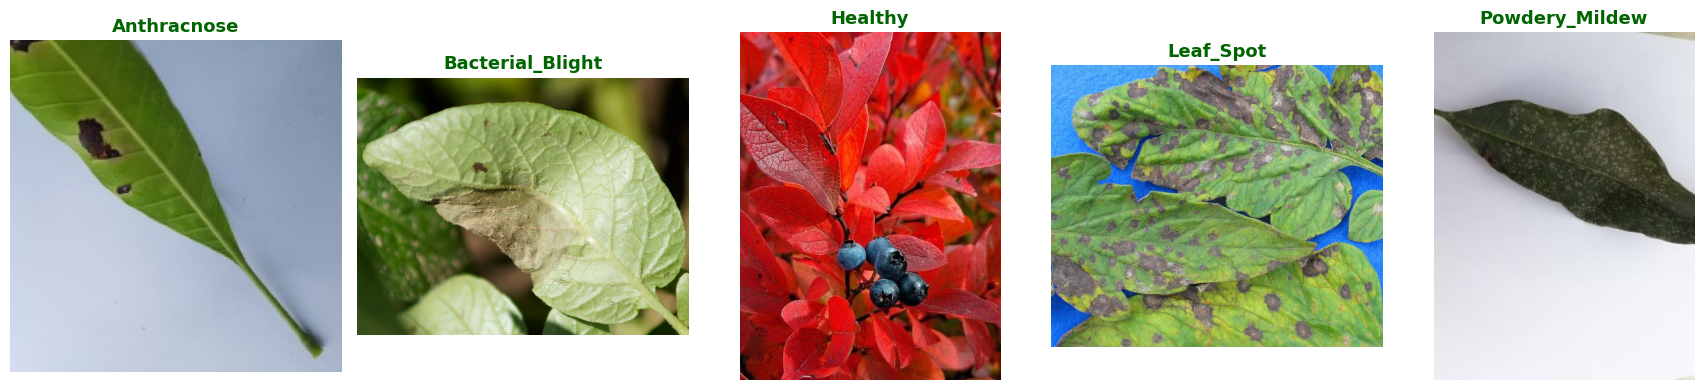

Đã lưu ảnh đại diện 5 nhóm bệnh tại: /content/drive/MyDrive/Dudoancaycanh_Disease/reports/Disease_Classes_Preview.png


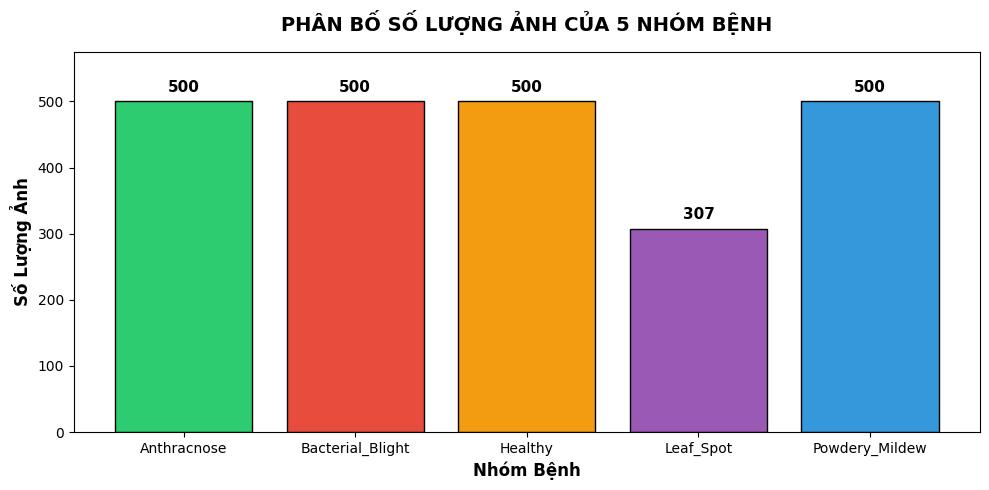

Đã lưu biểu đồ phân bố tại: /content/drive/MyDrive/Dudoancaycanh_Disease/reports/Disease_Distribution.png



In [ ]:
# ==============================================================================
# CHƯƠNG 4: TRỰC QUAN HÓA BỘ DỮ LIỆU (SAMPLE PREVIEW & PHÂN BỐ)
# ==============================================================================
import matplotlib.pyplot as plt
import collections

print("\nĐANG VẼ BỨC TRANH MẪU CỦA 5 NHÓM BỆNH...")
class_samples = {}
for path, label in full_dataset.samples:
    if label not in class_samples:
        class_samples[label] = path
    if len(class_samples) == NUM_CLASSES:
        break

fig, axes = plt.subplots(1, NUM_CLASSES, figsize=(NUM_CLASSES * 3.5, 4))
if NUM_CLASSES == 1:
    axes = [axes]

for idx in range(NUM_CLASSES):
    img_path = class_samples[idx]
    img = Image.open(img_path).convert("RGB")
    axes[idx].imshow(img)
    axes[idx].set_title(classes[idx], fontsize=13, fontweight='bold', color='darkgreen')
    axes[idx].axis('off')

plt.tight_layout()
sample_grid_path = os.path.join(DIRS['reports'], "Disease_Classes_Preview.png")
plt.savefig(sample_grid_path, dpi=150)
plt.show()
print(f"Đã lưu ảnh đại diện 5 nhóm bệnh tại: {sample_grid_path}")

# Vẽ biểu đồ phân bố số lượng ảnh
class_counts_dict = collections.Counter(targets)
counts = [class_counts_dict[i] for i in range(NUM_CLASSES)]

plt.figure(figsize=(10, 5))
bars = plt.bar(classes, counts, color=['#2ecc71', '#e74c3c', '#f39c12', '#9b59b6', '#3498db'], edgecolor='black')
plt.title("PHÂN BỐ SỐ LƯỢNG ẢNH CỦA 5 NHÓM BỆNH", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Nhóm Bệnh", fontsize=12, fontweight='bold')
plt.ylabel("Số Lượng Ảnh", fontsize=12, fontweight='bold')

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 10, int(yval),
             ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.margins(y=0.15)
plt.tight_layout()
distribution_path = os.path.join(DIRS['reports'], "Disease_Distribution.png")
plt.savefig(distribution_path, dpi=150)
plt.show()
print(f"Đã lưu biểu đồ phân bố tại: {distribution_path}\n")

In [ ]:
!pip install -q onnxscript


In [ ]:
# ==============================================================================
# CHƯƠNG 5: VÒNG LẶP HUẤN LUYỆN ĐA MÔ HÌNH (AUTO EXPERIMENT RUNNER)
# ==============================================================================
import timm
import torch.nn as nn
import time
import datetime
import warnings
import json
import gc
from tqdm.auto import tqdm
from torch.amp import GradScaler, autocast
from sklearn.metrics import f1_score, precision_score, recall_score, confusion_matrix, roc_curve, ConfusionMatrixDisplay
from sklearn.preprocessing import label_binarize
import matplotlib.gridspec as gridspec

warnings.filterwarnings("ignore")

def build_model(model_name, num_classes):
    model = timm.create_model(model_name, pretrained=True, num_classes=num_classes, drop_rate=DROPOUT_RATE)
    head = model.get_classifier()
    if hasattr(head, 'weight') and head.weight is not None:
        nn.init.xavier_uniform_(head.weight)
    if hasattr(head, 'bias') and head.bias is not None:
        nn.init.zeros_(head.bias)
    return model

for current_model in MODELS_TO_TRAIN:
    print(f"\n{'='*60}")
    print(f"BẮT ĐẦU HUẤN LUYỆN MÔ HÌNH: {current_model.upper()}")
    print(f"{'='*60}")

    model = build_model(current_model, NUM_CLASSES).to(device)
    timestamp = datetime.datetime.now().strftime("%Y-%m-%d_%H-%M-%S")
    EXP_DIR = os.path.join(DIRS['experiments'], f"{timestamp}_{current_model}")
    os.makedirs(EXP_DIR, exist_ok=True)

    head_params = [p for n, p in model.named_parameters() if 'head' in n or 'classifier' in n or 'fc' in n]
    backbone_params = [p for n, p in model.named_parameters() if not ('head' in n or 'classifier' in n or 'fc' in n)]
    opt_params = [{'params': backbone_params, 'lr': BACKBONE_LR}, {'params': head_params, 'lr': LEARNING_RATE}]

    optimizer = torch.optim.AdamW(opt_params, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
    criterion = nn.CrossEntropyLoss()
    scaler = GradScaler('cuda', enabled=MIXED_PRECISION)

    best_acc = 0.0
    start_epoch = 0
    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
    prev_val_loss, prev_val_acc = "N/A", "N/A"

    # Auto-Resume chống ngắt kết nối
    last_ckpt_path = os.path.join(DIRS['checkpoints'], f'last_disease_{current_model}.pth')
    if os.path.exists(last_ckpt_path):
        print(f"Đang phục hồi tiến độ cho {current_model}...")
        try:
            ckpt = torch.load(last_ckpt_path)
            model.load_state_dict(ckpt['model_state'])
            optimizer.load_state_dict(ckpt['optimizer_state'])
            scheduler.load_state_dict(ckpt['scheduler_state'])
            scaler.load_state_dict(ckpt['scaler_state'])
            start_epoch = ckpt['epoch'] + 1
            best_acc = ckpt['best_acc']
            history = ckpt['history']
            print(f"Đã khôi phục thành công! Tiếp tục từ Epoch {start_epoch+1}")
        except Exception as e:
            print("Không thể đọc file phục hồi, bắt đầu lại từ đầu.")

    # Vòng lặp huấn luyện
    for epoch in range(start_epoch, EPOCHS):
        since = time.time()

        # --- TRAIN ---
        model.train()
        train_loss, train_correct = 0.0, 0
        pbar = tqdm(train_loader, desc=f"[{current_model}] Epoch {epoch+1}/{EPOCHS}")
        for inputs, labels in pbar:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            with autocast('cuda', enabled=MIXED_PRECISION):
                outputs = model(inputs)
                loss = criterion(outputs, labels)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            train_loss += loss.item() * inputs.size(0)
            _, preds = torch.max(outputs, 1)
            train_correct += torch.sum(preds == labels.data).item()

            running_acc = train_correct / ((pbar.n + 1) * BATCH_SIZE)
            current_lr = optimizer.param_groups[0]['lr']
            pbar.set_postfix({
                'T_Loss': f"{loss.item():.4f}",
                'T_Acc': f"{running_acc*100:.1f}%",
                'V_Loss': prev_val_loss,
                'V_Acc': prev_val_acc,
                'LR': f"{current_lr:.1e}"
            })

        scheduler.step()
        epoch_train_loss = train_loss / len(train_ds)
        epoch_train_acc = train_correct / len(train_ds)

        # --- VAL ---
        model.eval()
        val_loss, val_correct = 0.0, 0
        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                with autocast('cuda', enabled=MIXED_PRECISION):
                    outputs = model(inputs)
                    loss = criterion(outputs, labels)
                val_loss += loss.item() * inputs.size(0)
                _, preds = torch.max(outputs, 1)
                val_correct += torch.sum(preds == labels.data).item()

        epoch_val_loss = val_loss / len(val_ds)
        epoch_val_acc = val_correct / len(val_ds)

        prev_val_loss = f"{epoch_val_loss:.4f}"
        prev_val_acc = f"{epoch_val_acc*100:.1f}%"

        print(f"TỔNG KẾT VÒNG {epoch+1:02d} | Train Loss: {epoch_train_loss:.4f} - Train Acc: {epoch_train_acc*100:.2f}% | Val Loss: {epoch_val_loss:.4f} - Val Acc: {epoch_val_acc*100:.2f}% | Thời gian: {time.time()-since:.0f}s")

        history['train_loss'].append(epoch_train_loss)
        history['val_loss'].append(epoch_val_loss)
        history['train_acc'].append(epoch_train_acc)
        history['val_acc'].append(epoch_val_acc)

        # Lưu checkpoint phục hồi
        torch.save({
            'epoch': epoch, 'model_state': model.state_dict(),
            'optimizer_state': optimizer.state_dict(), 'scheduler_state': scheduler.state_dict(),
            'scaler_state': scaler.state_dict(), 'best_acc': best_acc, 'history': history
        }, last_ckpt_path)

        if epoch_val_acc > best_acc:
            best_acc = epoch_val_acc
            best_model_path = os.path.join(DIRS['checkpoints'], f'best_disease_{current_model}.pth')
            torch.save(model.state_dict(), best_model_path)
            print(f"--> KỶ LỤC MỚI! Đã lưu checkpoint ({best_acc*100:.2f}%)")

    # --- ĐÁNH GIÁ ĐỘC LẬP TRÊN TEST SET & VẼ MASTER DASHBOARD ---
    print(f"\nĐang vẽ Master Dashboard học thuật cho {current_model}...")
    model.load_state_dict(torch.load(os.path.join(DIRS['checkpoints'], f'best_disease_{current_model}.pth')))
    model.eval()

    y_true, y_pred, y_conf = [], [], []
    start_time = time.time()
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs = inputs.to(device)
            with autocast('cuda', enabled=MIXED_PRECISION):
                outputs = model(inputs)
            probs = torch.softmax(outputs, dim=1)
            conf, preds = torch.max(probs, 1)
            y_true.extend(labels.numpy())
            y_pred.extend(preds.cpu().numpy())
            y_conf.extend(conf.cpu().numpy())

    total_time = time.time() - start_time
    fps = len(test_ds) / total_time
    latency = (total_time / len(test_ds)) * 1000
    test_acc = sum(np.array(y_true) == np.array(y_pred)) / len(y_true)
    f1 = f1_score(y_true, y_pred, average='macro')
    prec = precision_score(y_true, y_pred, average='macro')
    rec = recall_score(y_true, y_pred, average='macro')

    # Vẽ Master Dashboard
    fig = plt.figure(figsize=(22, 18))
    gs = gridspec.GridSpec(4, 2, height_ratios=[0.5, 3, 4, 1])
    fig.suptitle(f"BẢNG ĐIỀU KHIỂN CHẨN ĐOÁN BỆNH: {current_model.upper()}", fontsize=26, fontweight='bold', y=0.98)

    ax_text = fig.add_subplot(gs[0, :])
    ax_text.axis('off')
    metrics_text = f"Test Accuracy: {test_acc*100:.2f}% | F1 Score: {f1*100:.2f}% | Precision: {prec*100:.2f}% | Recall: {rec*100:.2f}%\nFPS: {fps:.0f} ảnh/s | Latency: {latency:.1f} ms"
    ax_text.text(0.5, 0.5, metrics_text, ha='center', va='center', fontsize=18, bbox=dict(boxstyle="round,pad=1", facecolor='#e8f5e9', edgecolor='#2e7d32'))

    ax_loss = fig.add_subplot(gs[1, 0])
    ax_loss.plot(history['train_loss'], label='Train Loss', color='#2e7d32', lw=2.5)
    ax_loss.plot(history['val_loss'], label='Val Loss', color='#c62828', lw=2.5)
    ax_loss.set_title("Loss Dynamics", fontsize=16, fontweight='bold'); ax_loss.legend(); ax_loss.grid(True)

    ax_acc = fig.add_subplot(gs[1, 1])
    ax_acc.plot(history['train_acc'], label='Train Acc', color='#2e7d32', lw=2.5)
    ax_acc.plot(history['val_acc'], label='Val Acc', color='#c62828', lw=2.5)
    ax_acc.set_title("Accuracy Dynamics", fontsize=16, fontweight='bold'); ax_acc.legend(); ax_acc.grid(True)

    ax_cm = fig.add_subplot(gs[2, 0])
    disp = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix(y_true, y_pred), display_labels=classes)
    disp.plot(ax=ax_cm, cmap='Greens', xticks_rotation=45, colorbar=False)
    ax_cm.set_title("Confusion Matrix (5 Nhóm Bệnh)", fontsize=16, fontweight='bold')

    ax_roc = fig.add_subplot(gs[2, 1])
    y_test_bin = label_binarize(y_true, classes=range(NUM_CLASSES))
    for i in range(NUM_CLASSES):
        fpr, tpr, _ = roc_curve(y_test_bin[:, i], np.array(y_conf) * (np.array(y_pred) == i))
        ax_roc.plot(fpr, tpr, lw=2, label=f'{classes[i]}')
    ax_roc.plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--')
    ax_roc.set_title("ROC Curve (5 Nhóm Bệnh)", fontsize=16, fontweight='bold'); ax_roc.legend(); ax_roc.grid(True)

    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    dash_path = os.path.join(EXP_DIR, f"Dashboard_{current_model}.png")
    plt.savefig(dash_path, dpi=300, bbox_inches='tight')
    plt.close(fig)

    # --- XUẤT FILE ONNX & TORCHSCRIPT ---
    print("Đang xuất mô hình sang định dạng ONNX và TorchScript...")
    onnx_name = "plant_disease_mobilenetv3.onnx" if "mobilenet" in current_model else f"{current_model}_disease.onnx"
    onnx_export_path = os.path.join(DIRS['exports'], onnx_name)

    dummy_input = torch.randn(1, 3, IMAGE_SIZE, IMAGE_SIZE).to(device)
    torch.onnx.export(
        model,
        dummy_input,
        onnx_export_path,
        export_params=True,
        opset_version=18,
        input_names=["input"],
        output_names=["output"],
        dynamic_axes={"input": {0: "batch_size"}, "output": {0: "batch_size"}}
    )
    print(f"Đã xuất ONNX thành công: {onnx_export_path}")

    with open(os.path.join(DIRS['exports'], "disease_labels.txt"), "w", encoding="utf-8") as f:
        for c in classes:
            f.write(f"{c}\n")

    with open(os.path.join(EXP_DIR, f"metrics_{current_model}.json"), "w") as f:
        json.dump({"Accuracy": test_acc, "F1": f1, "Precision": prec, "Recall": rec, "FPS": fps, "Latency": latency}, f)

    del model, optimizer, scheduler, scaler
    torch.cuda.empty_cache()
    gc.collect()

print("\nTẤT CẢ CÁC MÔ HÌNH CHẨN ĐOÁN BỆNH ĐÃ ĐƯỢC HUẤN LUYỆN VÀ LƯU VÀO GOOGLE DRIVE!")


BẮT ĐẦU HUẤN LUYỆN MÔ HÌNH: MOBILENETV3_LARGE_100
Đang phục hồi tiến độ cho mobilenetv3_large_100...
Đã khôi phục thành công! Tiếp tục từ Epoch 16

Đang vẽ Master Dashboard học thuật cho mobilenetv3_large_100...
Đang xuất mô hình sang định dạng ONNX và TorchScript...
[torch.onnx] Obtain model graph for `MobileNetV3([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `MobileNetV3([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...
[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅
Đã xuất ONNX thành công: /content/drive/MyDrive/Dudoancaycanh_Disease/exports/plant_disease_mobilenetv3.onnx

BẮT ĐẦU HUẤN LUYỆN MÔ HÌNH: TF_EFFICIENTNETV2_B0
Đang phục hồi tiến độ cho tf_efficientnetv2_b0...
Đã khôi phục thành công! Tiếp tục từ Epoch 7


[tf_efficientnetv2_b0] Epoch 7/15:   0%|          | 0/57 [00:00<?, ?it/s]

TỔNG KẾT VÒNG 07 | Train Loss: 0.0210 - Train Acc: 98.21% | Val Loss: 0.2810 - Val Acc: 91.34% | Thời gian: 32s


[tf_efficientnetv2_b0] Epoch 8/15:   0%|          | 0/57 [00:00<?, ?it/s]

TỔNG KẾT VÒNG 08 | Train Loss: 0.0089 - Train Acc: 98.70% | Val Loss: 0.2703 - Val Acc: 91.34% | Thời gian: 37s


[tf_efficientnetv2_b0] Epoch 9/15:   0%|          | 0/57 [00:00<?, ?it/s]

... (41 outputs left out)

[ghostnetv2_100] Epoch 14/15:   0%|          | 0/57 [00:00<?, ?it/s]

TỔNG KẾT VÒNG 14 | Train Loss: 0.0380 - Train Acc: 97.40% | Val Loss: 0.2769 - Val Acc: 91.34% | Thời gian: 35s


[ghostnetv2_100] Epoch 15/15:   0%|          | 0/57 [00:00<?, ?it/s]

TỔNG KẾT VÒNG 15 | Train Loss: 0.0396 - Train Acc: 97.45% | Val Loss: 0.2876 - Val Acc: 91.34% | Thời gian: 33s

Đang vẽ Master Dashboard học thuật cho ghostnetv2_100...
Đang xuất mô hình sang định dạng ONNX và TorchScript...
[torch.onnx] Obtain model graph for `GhostNet([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `GhostNet([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...
[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅
Đã xuất ONNX thành công: /content/drive/MyDrive/Dudoancaycanh_Disease/exports/ghostnetv2_100_disease.onnx

TẤT CẢ CÁC MÔ HÌNH CHẨN ĐOÁN BỆNH ĐÃ ĐƯỢC HUẤN LUYỆN VÀ LƯU VÀO GOOGLE DRIVE!


ĐANG TỔNG HỢP KẾT QUẢ TỪ TẤT CẢ MÔ HÌNH BỆNH HỌC...


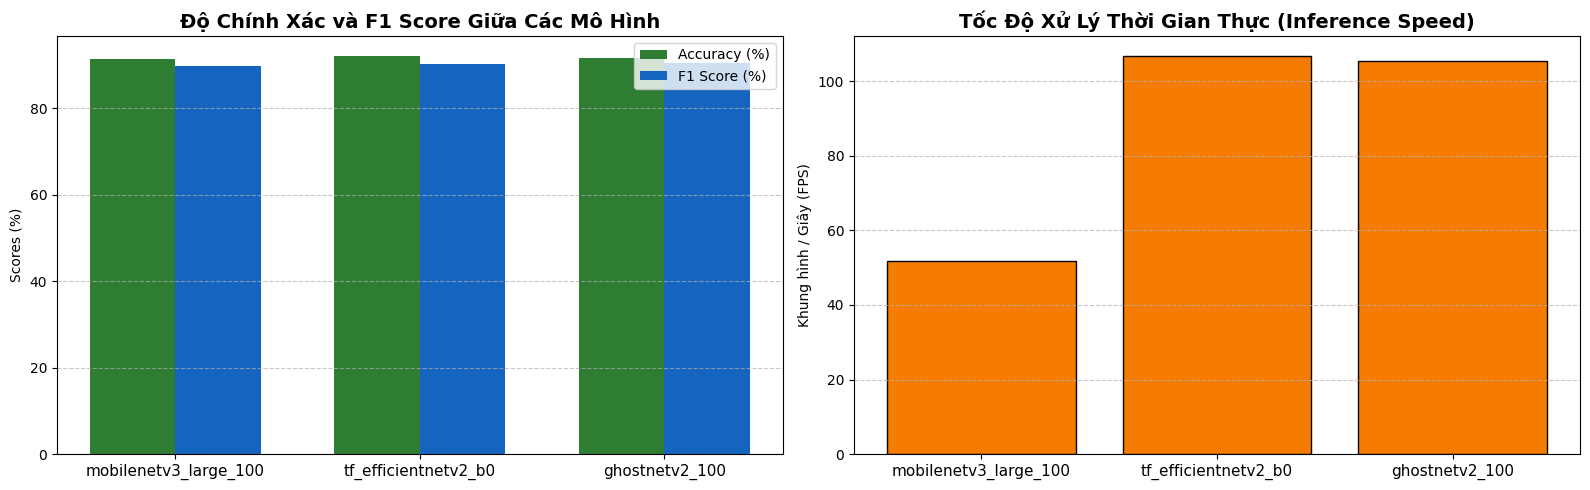

Đã xuất biểu đồ so sánh tổng thể tại: /content/drive/MyDrive/Dudoancaycanh_Disease/GLOBAL_DISEASE_COMPARISON.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Đã kích hoạt tải file mô hình về máy tính!


In [ ]:
# ==============================================================================
# CHƯƠNG 6: SO SÁNH TỔNG HỢP & TẢI MÔ HÌNH VỀ MÁY TÍNH
# ==============================================================================
import os
import json
import matplotlib.pyplot as plt
import numpy as np

print("ĐANG TỔNG HỢP KẾT QUẢ TỪ TẤT CẢ MÔ HÌNH BỆNH HỌC...")
all_metrics = {}
for root, dirs, files in os.walk(DIRS['experiments']):
    for file in files:
        if file.startswith("metrics_") and file.endswith(".json"):
            model_n = file.replace("metrics_", "").replace(".json", "")
            with open(os.path.join(root, file), "r") as f:
                all_metrics[model_n] = json.load(f)

if len(all_metrics) >= 1:
    models = list(all_metrics.keys())
    acc_scores = [all_metrics[m]['Accuracy']*100 for m in models]
    f1_scores = [all_metrics[m]['F1']*100 for m in models]
    fps_scores = [all_metrics[m]['FPS'] for m in models]

    fig, ax = plt.subplots(1, 2, figsize=(16, 5))
    x = np.arange(len(models))
    width = 0.35
    ax[0].bar(x - width/2, acc_scores, width, label='Accuracy (%)', color='#2e7d32')
    ax[0].bar(x + width/2, f1_scores, width, label='F1 Score (%)', color='#1565c0')
    ax[0].set_ylabel('Scores (%)')
    ax[0].set_title('Độ Chính Xác và F1 Score Giữa Các Mô Hình', fontweight='bold', fontsize=14)
    ax[0].set_xticks(x)
    ax[0].set_xticklabels(models, fontsize=11)
    ax[0].legend()
    ax[0].grid(axis='y', linestyle='--', alpha=0.7)

    ax[1].bar(x, fps_scores, color='#f57c00', edgecolor='black')
    ax[1].set_ylabel('Khung hình / Giây (FPS)')
    ax[1].set_title('Tốc Độ Xử Lý Thời Gian Thực (Inference Speed)', fontweight='bold', fontsize=14)
    ax[1].set_xticks(x)
    ax[1].set_xticklabels(models, fontsize=11)
    ax[1].grid(axis='y', linestyle='--', alpha=0.7)

    plt.tight_layout()
    compare_path = os.path.join(DRIVE_ROOT, "GLOBAL_DISEASE_COMPARISON.png")
    plt.savefig(compare_path, dpi=300)
    plt.show()
    print(f"Đã xuất biểu đồ so sánh tổng thể tại: {compare_path}")

# Tải file ONNX và nhãn về máy
try:
    from google.colab import files
    best_onnx = os.path.join(DIRS['exports'], "plant_disease_mobilenetv3.onnx")
    lbl_file = os.path.join(DIRS['exports'], "disease_labels.txt")
    if os.path.exists(best_onnx):
        files.download(best_onnx)
    if os.path.exists(lbl_file):
        files.download(lbl_file)
    print("Đã kích hoạt tải file mô hình về máy tính!")
except Exception as e:
    print(f"Mô hình đã được lưu an toàn trên Google Drive tại: {DIRS['exports']}")